# Программирование для всех <br>(основы работы с Python)

*Алла Тамбовцева*

## Практикум 7. Парсинг HTML с BeautifulSoup: поиск по тэгам и атрибутам

Мы уже немного познакомились со структурой html-страниц, теперь попробуем выгрузить информацию из более интересной страницы, а точнее, с сайта [nplus1.ru](https://nplus1.ru/). Наша задача – выгрузить недавние новости в датафрейм `pandas`, чтобы потом сохранить все в файл CSV.

Для работы нам снова понадобится модуль `requests` для отправки запросов, для «подключения» к странице и получения ее содержимого в виде строки, и функция `BeautifulSoup` из библиотеки `bs4` для удобного поиска по полученной строке:

In [1]:
import requests
from bs4 import BeautifulSoup

Сохраним ссылку на главную страницу в переменную `main` и отправим запрос к ней с помощью функции `get()` из `requests`:

In [2]:
main = "https://nplus1.ru/"
page = requests.get(main)
# page = requests.get(main, verify = False)

Заберём исходный код страницы и преобразуем строку с ним в объект `BeautifulSoup`:

In [3]:
soup = BeautifulSoup(page.text)

Чтобы сгрузить все новости с главной страницы сайта, нужно собрать все ссылки на страницы с этими новостями. Ссылки в html-файле всегда заключены в тэг `<a></a>` и имеют атрибут `href`. Найдем кусочки кода HTML, соответствующие всем ссылкам на главной странице сайта:

In [4]:
links_raw = soup.find_all("a") 
links_raw[10:20]  # несколько штук для примера

[<a class="hover:underline transition-colors duration-75" href="https://nplus1.ru/search?tags=880">Астрономия</a>,
 <a class="hover:underline transition-colors duration-75" href="https://nplus1.ru/search?tags=768">Генетика</a>,
 <a class="hover:underline transition-colors duration-75" href="https://nplus1.ru/search?tags=890">Математика</a>,
 <a class="hover:underline transition-colors duration-75" href="https://nplus1.ru/search?tags=871">Космонавтика</a>,
 <a class="hover:underline transition-colors duration-75" href="https://nplus1.ru/search?tags=876">Археология</a>,
 <a class="hover:underline transition-colors duration-75" href="https://nplus1.ru/search?tags=775">Нейронауки</a>,
 <a class="hover:underline transition-colors duration-75" href="https://nplus1.ru/search?tags=767">На мышах</a>,
 <a class="hover:underline transition-colors duration-75" href="https://nplus1.ru/search?tags=771">Звук</a>,
 <a class="hover:underline transition-colors duration-75" href="https://nplus1.ru/search

Каждый элемент возвращаемого списка имеет тип `BeautifulSoup` и структуру, очень похожую на словарь. Например, ссылка `<a class="hover:underline transition-colors duration-75" href="/search/empty/768">Генетика</a>` изнутри выглядит как словарь следующего вида:

    {'href' : '/search/empty/768', 
     'class' : 'hover:underline transition-colors duration-75'}.
    
Как мы помним, значение по ключу из словаря можно вызвать с помощью метода `.get()`. Давайте извлечем значения по ключу `href` из каждого элемента списка `links`:

In [5]:
links = [li.get("href") for li in links_raw]
links[10:20]  # несколько штук для примера

['https://nplus1.ru/search?tags=880',
 'https://nplus1.ru/search?tags=768',
 'https://nplus1.ru/search?tags=890',
 'https://nplus1.ru/search?tags=871',
 'https://nplus1.ru/search?tags=876',
 'https://nplus1.ru/search?tags=775',
 'https://nplus1.ru/search?tags=767',
 'https://nplus1.ru/search?tags=771',
 'https://nplus1.ru/search?tags=772',
 'https://nplus1.ru/search?tags=778']

Ссылок в списке выше много. Но нам нужны только новости – ссылки, которые начинаются с `https://nplus1.ru/news`. Создадим пустой список `news` и будем добавлять в него только ссылки, которые удовлетворяют этому условию.

In [6]:
news = []
for li in links:
    if "https://nplus1.ru/news/" in li:
        news.append(li)

In [7]:
print(news[0:10])

['https://nplus1.ru/news/2026/11/17/social-connectivity-in-chimp', 'https://nplus1.ru/news/2026/11/18/bdnf-mrna-lnp', 'https://nplus1.ru/news/2026/11/18/interrupting-continuous-walking', 'https://nplus1.ru/news/2026/11/18/voyager-1-one-light-day', 'https://nplus1.ru/news/2026/11/18/hera-didim-first-data', 'https://nplus1.ru/news/2026/11/18/eagles-vs-baboons', 'https://nplus1.ru/news/2026/11/18/no-cbd-for-behavioral-problems', 'https://nplus1.ru/news/2026/11/18/onychophora-vs-arthropoda', 'https://nplus1.ru/news/2026/11/18/hayabusa-2-new-final-target', 'https://nplus1.ru/news/2026/11/18/car-t-vs-sle']


Теперь наша задача сводится к следующему: изучить одну страницу с новостью, научиться из нее вытаскивать текст и всю необходимую информацию, а потом применить весь набор действий к каждой ссылке из `news` в цикле. Посмотрим на новость с индексом 0, у вас может быть другая, новости обновляются.

In [8]:
link0 = news[0]
print(link0)

https://nplus1.ru/news/2026/11/17/social-connectivity-in-chimp


### Задача 1

Отправьте запрос к странице по ссылке `link0` с одной новостью, получите результат в виде объекта `BeautifulSoup` и сохраните его как `soup0`.

In [9]:
page0 = requests.get(link0)
soup0 = BeautifulSoup(page0.text)
# page0 = requests.get(link0, verify = False)

### Задача 2

Найдите заголовок новости и сохраните его в переменную `title`.

In [10]:
title = soup0.find("title")
print(title)

<title>Шимпанзе расширили круг друзей накануне совместного патрулирования границ. Они увеличили число партнеров по игре и грумингу</title>


### Задача 3

Найдите имя автора новости и дату её публикации. Сохраните их в `author` и `date` соответственно.

In [11]:
author = soup0.find("meta", {"name" : "author"}).get("content")
date = soup0.find("meta", {"itemprop" : "datePublished"}).get("content")

print(author, date)

Катерина Петрова 2026-11-17


### Задача 4

Найдите сложность новости и рубрики, к которым она относится. Сохраните сложность в переменную `diffc`. Рубрики сначала можно сохранить в список, а затем его элементы объединить в одну строку `rubs`.

**Подсказка:** чтобы упростить себе жизнь, найдите сначала раздел (`div`), в котором на странице хранится дата и время публикации, сложность и рубрики, а затем выполняйте поиск в рамках этого раздела.

In [12]:
# сам раздел
div = soup0.find("div",
           {"class" : "flex flex-wrap lg:mb-10 gap-2 text-tags xl:pr-9"})
div

<div class="flex flex-wrap lg:mb-10 gap-2 text-tags xl:pr-9">
<span class="relative before:block before:w-px before:bg-current before:h-4 before:absolute before:left-0 group pl-2 flex inline-flex items-center">
<span class="group-hover:text-main transition-colors duration-75">19:02</span>
</span>
<a class="relative before:block before:w-px before:bg-current before:h-4 before:absolute before:left-0 group pl-2 flex inline-flex items-center" href="/news/2026/11/17">
<span class="group-hover:text-main transition-colors duration-75">17.11.26</span>
</a>
<a class="relative before:block before:w-px before:bg-current before:h-4 before:absolute before:left-0 group pl-2 flex inline-flex items-center" href="/material/difficulty/2">
<svg class="w-4 h-4 mr-1 group-hover:text-main transition-colors duration-75 stroke-current">
<use xlink:href="#n1_star"></use>
</svg>
<span class="group-hover:text-main transition-colors duration-75">2.5</span>
</a>
<a class="relative before:block before:w-px before:b

In [13]:
# находим все фрагменты <span>
# элемент с индексом 3 содержит сложность,
# оттуда извлекаем текст

diffc = div.find_all("span")[3].text
print(diffc)

2.5


In [14]:
# рубрики идут после сложности, значит, индекс 4
# однако рубрик может быть несколько,
# чтобы забрать все, выбираем все элементы с 4 до конца списка
# из каждого элемента извлекаем текст и склеиваем

rubs_raw = div.find_all("span")[4:]
rubs_list = [r.text for r in rubs_raw]
rubs = ", ".join(rubs_list)
print(rubs)

Зоология


### Задача 5

Соберите из абзацев текст новости и сохраните его в переменную `text`. Избавьтесь от постронних символов (`\xa0`, `\n`) в тексте. 

In [15]:
soup0.find_all("p", {"class" : "mb-6"})

[<p class="text-28 md:text-44 xl:text-54 font-spectral text-main-gray mb-6 break-words">Они увеличили число партнеров по игре и грумингу</p>,
 <p class="mb-6">Приматологи из Германии и Франции обнаружили, что накануне патрулирования границ дикие шимпанзе расширяют свои социальные сети. В дни, когда приматы совместно защищали территорию, они участвовали в играх и груминге с большим количеством партнеров и чаще занимались групповым грумингом. Препринт статьи <a href="https://www.biorxiv.org/content/10.64898/2026.06.15.732266v2.full" rel="noreferrer noopener" target="_blank">доступен</a> на bioRxiv.org.</p>,
 <p class="mb-6">Способность объединяться и сотрудничать со многими сородичами одновременно, критически важная для людей, играет значимую роль и в жизни других социальных приматов. Так, шимпанзе кооперируются с сородичами из своей группы для защиты и захвата территорий. Такие объединения требуют достаточной сплоченности внутри группы, поскольку чем больше особей объединится, тем больш

In [16]:
# mb-6 встречается также в class для подзаголовка статьи,
# чтобы не забирать его, берем элементы, начиная со второго (1:)
# далее из каждого элемента списка забираем текст абзаца

pars_raw = soup0.find_all("p", {"class" : "mb-6"})[1:]
pars_list = [p.text for p in pars_raw]
text = " ".join(pars_list)
text = text.replace("\xa0", " ").replace("\n", " ")
print(text)

Приматологи из Германии и Франции обнаружили, что накануне патрулирования границ дикие шимпанзе расширяют свои социальные сети. В дни, когда приматы совместно защищали территорию, они участвовали в играх и груминге с большим количеством партнеров и чаще занимались групповым грумингом. Препринт статьи доступен на bioRxiv.org. Способность объединяться и сотрудничать со многими сородичами одновременно, критически важная для людей, играет значимую роль и в жизни других социальных приматов. Так, шимпанзе кооперируются с сородичами из своей группы для защиты и захвата территорий. Такие объединения требуют достаточной сплоченности внутри группы, поскольку чем больше особей объединится, тем больше будет шансов на успех — а значит ниже риск пострадать или погибнуть для каждого отдельного участника. На многих видах, в том числе и на шимпанзе, показано, что связь между особями усиливают аффилиативные взаимодействия — игра, груминг или телесный контакт. Однако чаще всего ученые смотрят на пары (ди

**Дополнение**

Как можно заметить, в текст статьи при таком подходе попал еще подзаголовок и начало следующей статьи, так ее фрагмент тоже есть на странице (обычная история для новостей или блогов).

Как избавиться от лишнего текста? Заметим, что после окончания текущей новости следует подзаголовок следующей (у заголовков нет тэга `<p>`, поэтому в перечне абзацев выше их нет) и её фрагмент. Поэтому для универсального удаления лишнего текста нужно забрать все элементы из `pars_raw` до подзаголовка.

In [17]:
# заберем все значения атрибута class -> classes
# сейчас в classes списки с элементами внутри class
# для каждого элемента в pars_list

classes = [p.get("class") for p in pars_raw]
print(classes)

[['mb-6'], ['mb-6'], ['mb-6'], ['mb-6'], ['mb-6'], ['mb-6'], ['mb-6'], ['text-28', 'md:text-44', 'xl:text-54', 'font-spectral', 'text-main-gray', 'mb-6', 'break-words'], ['mb-6']]


In [18]:
# переберем все элементы и найдем индекс того, где 
# есть text-main-gray – такое есть только у подзаголовков,
# они серого цвета, а не черного

for c in classes:
    if "text-main-gray" in c:
        i = classes.index(c)
        break
        
print(i)

7


In [19]:
# заберем все элементы до i
# теперь это абзацы только первой новости

pars_upd = pars_raw[:i]
text = " ".join([p.text for p in pars_upd])
text = text.replace("\xa0", " ").replace("\n", " ")
print(text)

Приматологи из Германии и Франции обнаружили, что накануне патрулирования границ дикие шимпанзе расширяют свои социальные сети. В дни, когда приматы совместно защищали территорию, они участвовали в играх и груминге с большим количеством партнеров и чаще занимались групповым грумингом. Препринт статьи доступен на bioRxiv.org. Способность объединяться и сотрудничать со многими сородичами одновременно, критически важная для людей, играет значимую роль и в жизни других социальных приматов. Так, шимпанзе кооперируются с сородичами из своей группы для защиты и захвата территорий. Такие объединения требуют достаточной сплоченности внутри группы, поскольку чем больше особей объединится, тем больше будет шансов на успех — а значит ниже риск пострадать или погибнуть для каждого отдельного участника. На многих видах, в том числе и на шимпанзе, показано, что связь между особями усиливают аффилиативные взаимодействия — игра, груминг или телесный контакт. Однако чаще всего ученые смотрят на пары (ди

### Задача 6

Напишите функцию `get_news()`, которая принимает на вход ссылку на страницу с одной новостью, а возвращает список из следующих характеристик: имя автора, дата публикации, сложность новости, рубрики, текст новости.

In [20]:
# правда, наша функция возвращает кортеж, а не список,
# но тут неважно

def get_news(link0):
    page0 = requests.get(link0, verify = False)
    soup0 = BeautifulSoup(page0.text)
    title = soup0.find("title").text.replace("\xa0", " ")
    author = soup0.find("meta", {"name" : "author"}).get("content")
    date = soup0.find("meta", {"itemprop" : "datePublished"}).get("content")
    div = soup0.find("div",
           {"class" : "flex flex-wrap lg:mb-10 gap-2 text-tags xl:pr-9"})
    diffc = div.find_all("span")[3].text
    rubs_raw = div.find_all("span")[4:]
    rubs_list = [r.text for r in rubs_raw]
    rubs = ", ".join(rubs_list)
    pars_raw = soup0.find_all("p", {"class" : "mb-6"})[1:]
    pars_list = [p.text for p in pars_raw]
    text = " ".join(pars_list)
    text = text.replace("\xa0", " ").replace("\n", " ")
    return [title, author, date, diffc, rubs, text]

In [21]:
# важно: стоит проверить работу перед запуском
get_news(news[2])

/opt/anaconda3/lib/python3.14/site-packages/urllib3/connectionpool.py:1110: InsecureRequestWarning: Unverified HTTPS request is being made to host 'nplus1.ru'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


['Короткие частые прогулки эффективнее длинных и редких улучшили толерантность к глюкозе. У людей с избыточным весом и ожирением',
 'Слава Гоменюк',
 '2026-11-18',
 '2.2',
 'Медицина',
 'Американские ученые сравнили эффективность разных форм физической активности и выяснили, что короткие (около пяти минут) прогулки быстрым шагом каждый час эффективнее повышают толерантность к глюкозе через шесть недель у людей с ожирением, чем одна прогулка длительностью 45 минут в день. При этом, как сообщается в журнале Obesity, ни одно из этих вмешательств не повышало чувствительность к инсулину.  Малоподвижный образ жизни, определяемый как любое поведение во время бодрствования, характеризующееся низкими энергетическими затратами (менее 1,5 метаболического эквивалента нагрузки) в положении сидя или лежа, считается важным фактором нарушения регуляции уровня глюкозы. По подсчетам ученых, взрослые люди в большинстве западных стран обычно проводят 8–12 часов в день в сидячем положении, и каждый дополни

**Дополнение**

Вариант функции с учетом дополнения из задачи №5 (плюс, с документацией для порядка):

In [22]:
def get_news(link0):
    """
    Parameters:
        link0 – url for one piece of news (string)
    Returns:
         a tuple of the following features:
            * new's title (string)
            * new's date (string)
            * new's author (string)
            * new's difficulty (string)
            * new's rubrics (string)
            * new's text (string)
    """
    page0 = requests.get(link0)
    soup0 = BeautifulSoup(page0.text)
    
    title = soup0.find("title").text.replace("\xa0", " ")
    date = soup0.find("meta", {"itemprop" : "datePublished"}).get("content")
    author = soup0.find("meta", {"name" : "author"}).get("content")
    div = soup0.find("div", {"class" : "flex flex-wrap lg:mb-10 gap-2 text-tags xl:pr-9"})
    spans = div.find_all("span")
    diffc = spans[3].text
    rubs_raw = spans[4:]
    rubs = ", ".join([r.text for r in rubs_raw])

    # для текста – более универсальный вариант без лишней новости
    pars_raw = soup0.find_all("p", {"class" : "mb-6"})[1:]
    classes = [p.get("class") for p in pars_raw]
    for c in classes:
        if "text-main-gray" in c:
            i = classes.index(c)
    pars_upd = pars_raw[:i]
    text = " ".join([p.text for p in pars_upd])
    text = text.replace("\xa0", " ").replace("\n", " ")
    
    return [title, author, date, diffc, rubs, text]

Отлично! Теперь осталось применить функцию ко всем ссылкам в списке `news`. Чтобы сайт не понял, что мы его автоматически грабим, будем выгружать новости постепенно – с задержкой в 1.2 секунды. Импортируем для этого функцию `sleep` :

In [23]:
from time import sleep

Теперь будем применять функцию в цикле к каждой ссылке в `news`, только с одним дополнением – добавленной конструкцией `try-except`, которая позволит продолжать исполнение цикла, если при применении функции Python столкнулся с ошибкой любого вида:

In [ ]:
info = []
for n in news:
    # пробуй исполнить следующий код
    try:
        res = get_news(n)
        info.append(res)
        #print(n)
    # если он вызвал ошибку любого вида, печатай сообщение и иди дальше
    except:
        print("Something went wrong")
        print(n)
    sleep(1.2)

Финальный штрих – импортируем `pandas` и преобразуемый полученный список списков в таблицу (датафрейм):

In [26]:
import pandas as pd

In [27]:
df = pd.DataFrame(info, 
                  columns = ["title", "author", "date", "diffc", "rubrics", "text"])
df

,title,author,date,diffc,rubrics,text
0,Шимпанзе расширили круг друзей накануне совмес...,Катерина Петрова,2026-11-17,2.5,Зоология,"Приматологи из Германии и Франции обнаружили, ..."
1,Назальный спрей заставил эпителий носовой поло...,Слава Гоменюк,2026-11-18,3.8,"Медицина, Биология",Австралийские ученые разработали терапевтическ...
2,Короткие частые прогулки эффективнее длинных и...,Слава Гоменюк,2026-11-18,2.2,Медицина,Американские ученые сравнили эффективность раз...
3,«Вояджер-1» удалился от Земли на световой день...,Александр Войтюк,2026-11-18,1.2,Космонавтика,18 ноября 2026 года в 13:16 по московскому вре...
4,Европейская межпланетная станция Hera рассмотр...,Александр Войтюк,2026-11-18,3.1,Космонавтика,Межпланетная станция Hera после прибытия к дво...
5,Зоологи допустили охоту орлов на взрослых самц...,Сергей Коленов,2026-11-18,3.8,"Зоология, Палеонтология","Зоологи предположили, что кафрские орлы, обита..."
6,Каннабидиол не улучшил поведение детей и подро...,Олег Лищук,2026-11-18,1.5,"Психология, Медицина",Катрина Уильямс (Katrina Williams) из Универси...
7,Сенокосцев и пещерного кузнечика заподозрили в...,Сергей Коленов,2026-11-18,2.8,Зоология,"Зоологи составили список животных, которые пит..."
8,«Хаябусе-2» сменили финальный астероид. У стан...,Александр Войтюк,2026-11-18,1.9,Космонавтика,Японская межпланетная станция «Хаябуса-2» не с...
9,Обобщенный анализ подтвердил эффективность CAR...,Олег Лищук,2026-11-18,3.1,Медицина,Американские ученые провели обновленный обобще...


Выведем техническое описание датафрейма, чтобы узнать, какие в нем типы столбцов:

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    48 non-null     str  
 1   author   48 non-null     str  
 2   date     48 non-null     str  
 3   diffc    48 non-null     str  
 4   rubrics  48 non-null     str  
 5   text     48 non-null     str  
dtypes: str(6)
memory usage: 340.5 KB


Все столбцы имеют тип `str` (или `object`, так в `pandas` более старой версии называется текст). Для названия, автора, текста статьи и рубрик это оправдано, а вот сложность статьи по-хорошему должна быть сохранена в виде дробных чисел. Дату тоже хорошо бы привести к типу `datetime`, чтобы мы смогли выполнять хронологическую сортировку новостей, строить всякие графики для динамики и извлекать из даты день недели. Но мы остановимся только на сложности. Изменим тип столбца на `float` и перезапишем столбец:

In [29]:
df["diffc"] = df["diffc"].astype(float)

# сработало
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   title    48 non-null     str    
 1   author   48 non-null     str    
 2   date     48 non-null     str    
 3   diffc    48 non-null     float64
 4   rubrics  48 non-null     str    
 5   text     48 non-null     str    
dtypes: float64(1), str(5)
memory usage: 340.3 KB


Теперь, пользуясь тем, что сложность представлена в числовом виде, можем построить для нее гистограмму:

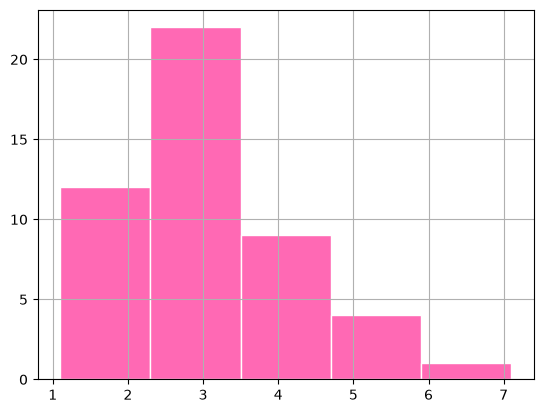

In [30]:
# теперь можно строить гистограмму
# bins = 5, пять столбцов
# color – цвет заливки
# edgecolor – цвет границ столбцов

df["diffc"].hist(color = "hotpink", edgecolor = "white", bins = 5);

Список названий цветов, которые поддерживаются графической библиотекой Python (активируется внутри `pandas`), можно найти [здесь](https://matplotlib.org/stable/gallery/color/named_colors.html).

Экспортируем таблицу в файлы CSV и Excel:

In [31]:
df.to_csv("nplus1.csv")

In [32]:
df.to_excel("nplus1.xlsx")

Теперь файлы `nplus1.csv` и `nplus1.xlsx` появились в рабочей папке (рядом с текущим `.ipynb`, видно в *Home* в Jupyter). Если по виду папки в *Home* непонятно, что это за папка, можно импортировать базовый модуль os для работы с операционной системой и запросить путь к текущей рабочей папке:

In [33]:
import os

# get current working directory

os.getcwd()

'/Users/allat/Documents/Кафедра высшей математики/2026-2027/Python для всех/weeks/09-week07'